In [53]:
cd ./wrkDir/s19/s19-1

[Errno 2] No such file or directory: './wrkDir/s19/s19-1'
/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [54]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask/'
pltDir='./plot/selBias/'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

Populating the interactive namespace from numpy and matplotlib


# Selection Bias of Resolution Cut
## Preparation

Read data and apply weak lensing. 90 degree rotation is applied for cuts except the resolution cut.

In [44]:
# Read catalog
dataP =   pd.read_hdf(inFname,mode='r')
data=dataP.to_records()

In [17]:
min_snr=10
max_snr=200
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.

wlmask2    =   utilities.galaxy_selector(catalog=data,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=False,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e
dataU2=data[wlmask2]

In [ ]:
dataU=data[data['wlmask_90rot']]

In [19]:
weight=utilities.get_weight_model(dataU)*dataU['weight']
weight2=utilities.get_weight_model(dataU2)*dataU2['weight']

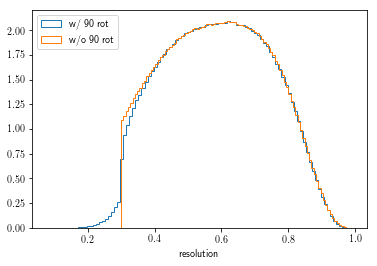

In [74]:
plt.hist(dataU['res'],bins=100,weights=weight,density=True,histtype='step',label='w/ 90 rot')
plt.hist(dataU2['res'],bins=100,weights=weight2,density=True,histtype='step',label='w/o 90 rot')
plt.xlabel('resolution')
plt.legend()

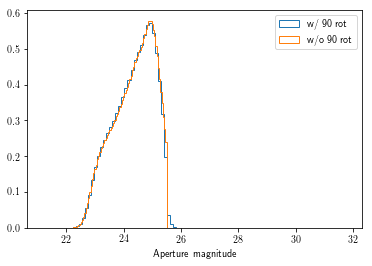

In [75]:
plt.hist(dataU['magA10'],bins=100,weights=weight,density=True,histtype='step',label='w/ 90 rot')
plt.hist(dataU2['magA10'],bins=100,weights=weight2,density=True,histtype='step',label='w/o 90 rot')
plt.xlabel('Aperture magnitude')
plt.legend()

In [76]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            utilities.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

def makePlotSelBias(obsname,dataU):
    nbin_1d=6
    shape_weight = utilities.get_weight_model(dataU)*dataU['weight']
    p_edges=np.zeros(nbin_1d)

    if obsname=="mag":
        xlabel='Cmodel Magnitude (lower limit)'
        cutplace=r'\rm{mag}=24.5'
        obs_cuts  =   np.linspace(20,22.5,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.025
        n_first_bin = np.sum(shape_weight[(obs >= 24.5 - bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs>=obs_cuts[i])]) * bin_size)
    elif obsname=="magA10":
        xlabel='Aperture Magnitude (lower limit)'
        cutplace=r'\rm{magA}=25.5'
        obs_cuts  =   np.linspace(23,24.5,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.025
        n_first_bin = np.sum(shape_weight[(obs >= 25.5 - bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs>=obs_cuts[i])]) * bin_size)
    elif obsname=="res":
        xlabel='Regaus resolution (upper limit)'
        cutplace=r'\rm{res}=0.3'
        obs_cuts  =   np.linspace(0.5,1.,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   0.01
        n_first_bin = np.sum(shape_weight[(obs <= 0.3 + bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs<=obs_cuts[i])]) * bin_size)
    elif obsname=="snr":
        xlabel='Cmodel SNR (upper limit)'
        cutplace=r'\rm{snr}=10'
        obs_cuts  =   np.linspace(80.,200.,nbin_1d)
        obs=dataU[obsname]
        bin_size  =   1.
        n_first_bin = np.sum(shape_weight[(obs <= 10. + bin_size)])
        for i in range(nbin_1d):
            p_edges[i] = n_first_bin / (np.sum(shape_weight[(obs<=obs_cuts[i])]) * bin_size)

    print(p_edges)
    shearBinName1=   os.path.join(pltDir,'shear_selbias_%s.npy' %obsname)
    shearBinName2=   os.path.join(pltDir,'shear_selbias_%s_90rot.npy' %obsname)

    m1,a1,sigm1,siga1=get_mc_bins(shearBinName1,nbin_1d)
    m2,a2,sigm2,siga2=get_mc_bins(shearBinName2,nbin_1d)


    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(1,2,1)
    ax.errorbar(obs_cuts, m1-m2,sigm1*np.sqrt(2.))
    ax.set_xlabel(xlabel,fontsize=15)
    ax.set_ylabel(r'$m_{\rm{sel}}$',fontsize=15)
    ax.set_title('Multiplicative bias')
    plt.grid()


    ax = fig.add_subplot(1,2,2)
    ax.errorbar(obs_cuts, a1-a2,siga1*np.sqrt(2.))
    ax.set_xlabel(xlabel,fontsize=15)
    ax.set_ylabel(r'$a_{\rm{sel}}$',fontsize=15)
    ax.set_title('Additive bias')
    plt.grid()
    plt.tight_layout()
    #plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))
    
    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(1,2,1)
    ax.errorbar(obs_cuts, (m1-m2)/p_edges,sigm1*np.sqrt(2.)/p_edges)
    plt.xlabel(xlabel,fontsize=15)
    plt.ylabel(r'$m_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
    plt.title('Multiplicative bias of selection')
    plt.grid()


    ax = fig.add_subplot(1,2,2)
    ax.errorbar(obs_cuts, (a1-a2)/p_edges,siga1*np.sqrt(2.)/p_edges)
    plt.xlabel(xlabel,fontsize=15)
    plt.ylabel(r'$a_{\rm{sel}}/p(%s)$' %cutplace,fontsize=15)
    plt.title('Additive bias of selection')
    plt.grid()
    plt.tight_layout()
    plt.savefig(os.path.join(pltDir,'selBias_%s.eps' %(obsname)))
    return

[0.24249644 0.25899883 0.28369229 0.32027796 0.37928119 0.4861877 ]


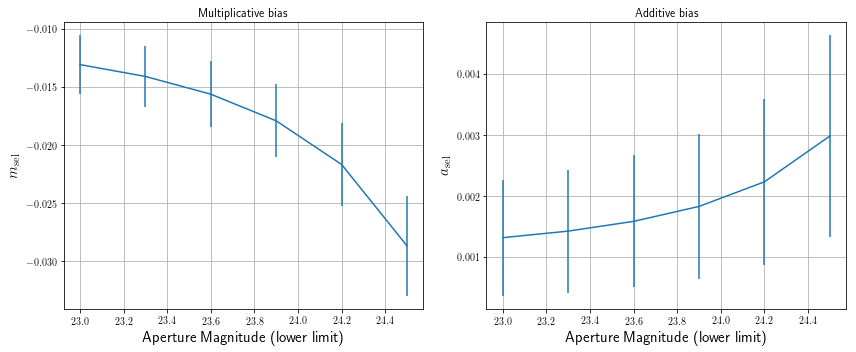

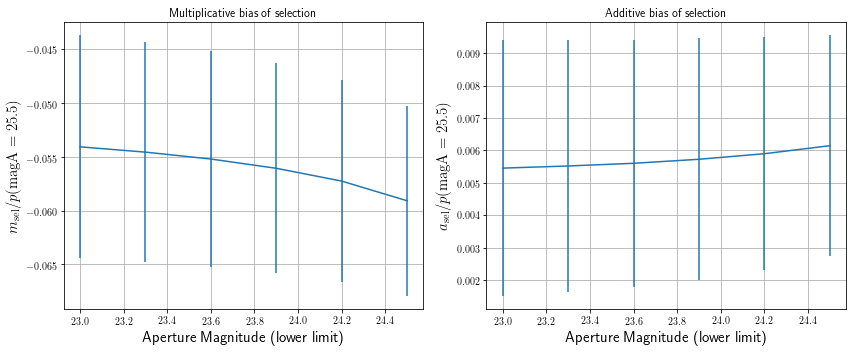

In [77]:
makePlotSelBias('magA10',dataU2)

[3.44898012 2.10625539 1.51271798 1.22026808 1.11431114 1.10463623]


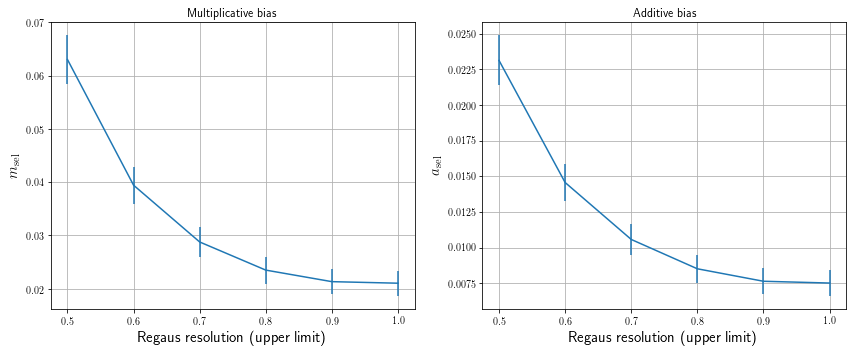

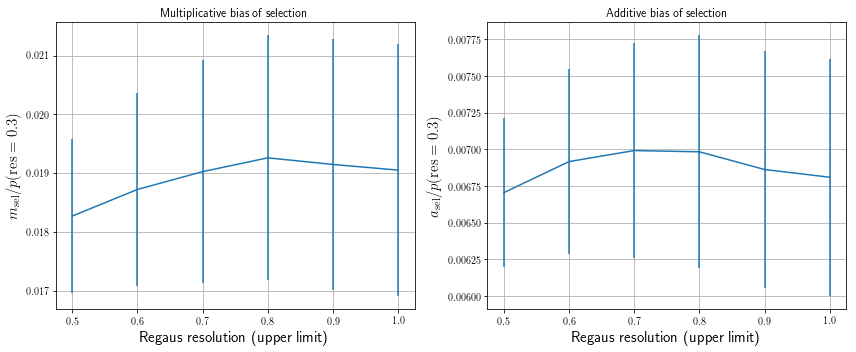

In [73]:
makePlotSelBias('res',dataU2)

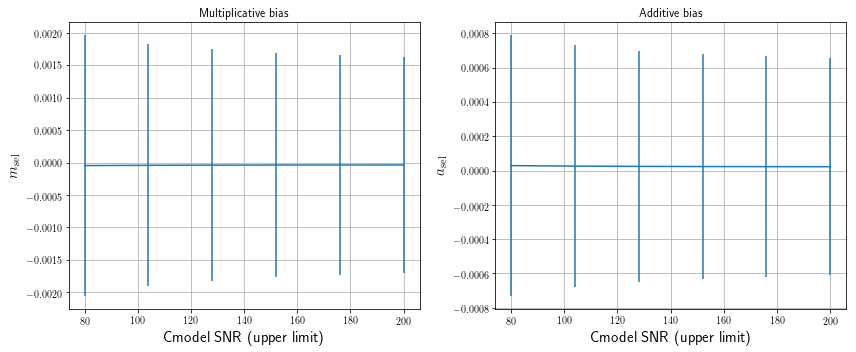

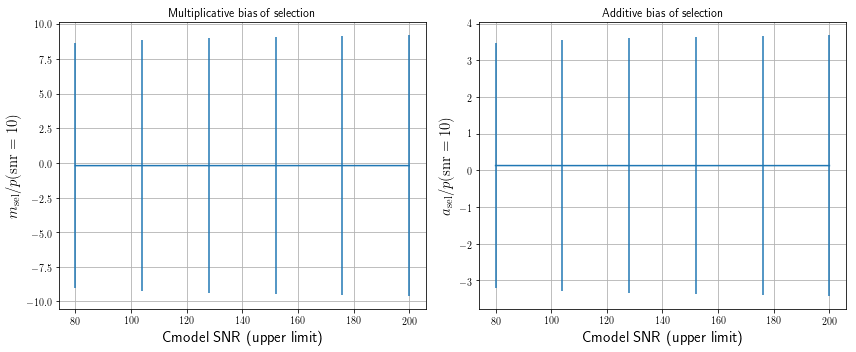

In [36]:
makePlotSelBias('snr',dataU2)

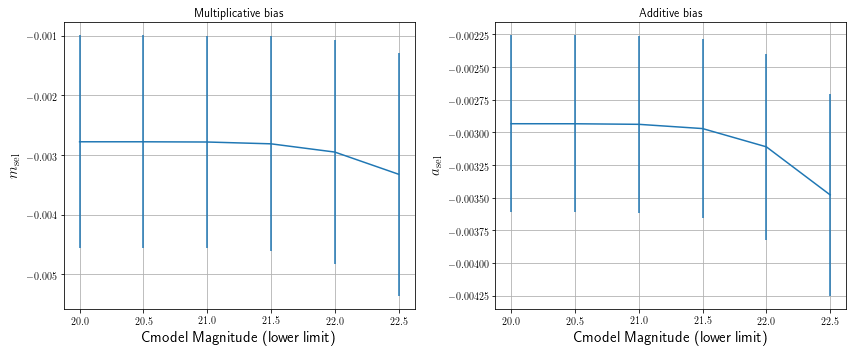

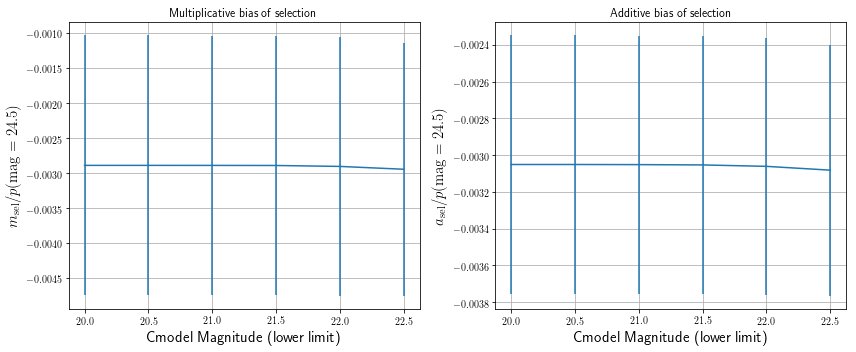

In [37]:
makePlotSelBias('mag',dataU2)

## S16A Estimation
$$A= 0.00865\pm 0.0026$$